# Практическая работа №2: Исследование подгрупп сетей. Сети аффилированности.

Выполнил студент гр. 4385 Семенченко Михаил Александрович. Вариант №9.

## Цель работы

Овладеть навыками работы с математическими пакетами для исследования подгрупп в социальных сетях, а также моделирования, отображения
и анализа сетей аффилированности.

###Основные формулы

Матрица инцидентности ($A$): таблица $n \times m$, где $a_{ij} = 1$, если актор $i$ участвует в событии $j$ (иначе $0$).

Матрица совместного участия ($P$): число общих событий у пары акторов: $P = A \cdot A^T$.

Матрица перекрытия ($O$): число общих акторов у пары событий: $O = A^T \cdot A$.

Степень участия актора ($d_i$): число событий у актора $i$: $d_i = \sum_{j=1}^{m} a_{ij}$.

Среднее участие актора ($\bar{d}$): $\bar{d} = \frac{1}{n} \sum_{i=1}^{n} d_i$.

Размер события ($s_j$): число акторов в событии $j$: $s_j = \sum_{i=1}^{n} a_{ij}$.

Средний размер события ($\bar{s}$): $\bar{s} = \frac{1}{m} \sum_{j=1}^{m} s_j$.

Плотность сети ($\Delta$): доля существующих связей $L$ от всех возможных между $N$ узлами: $\Delta = \frac{2L}{N(N - 1)}$.

Диаметр сети ($D$): самый длинный из кратчайших путей между любыми двумя узлами: $D = \max_{u, v} d(u, v)$.

Отношение шансов ($\text{OR}$): сила связи между парой событий: $\text{OR} = \frac{a \cdot d}{b \cdot c}$ ($a$ - в обоих, $b$ - только в 1-м, $c$ - только во 2-м, $d$ - ни в одном).

Логарифм отношения шансов ($\log\text{OR}$): $\ln \left( \frac{(a + 0.5)(d + 0.5)}{(b + 0.5)(c + 0.5)} \right)$.

$k$-ядро: максимальный подграф, где у каждой вершины не меньше $k$ связей внутри него ($\deg(v) \ge k$).

Модулярность ($Q$): оценка качества разбиения на кластеры: $Q = \frac{1}{2L} \sum_{i, j} \left( A_{ij} - \frac{k_i k_j}{2L} \right) \delta(c_i, c_j)$.

## Постановка задачи

С помощью математических пакетов и соответствующих библиотек провести анализ заданных социальных сетей на предмет подгрупп. Провести
исследование сети аффилированности CEO. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

Пункты работы, как правило, выполняются с помощью кода.

1. Из файла florentine_business.csv
и извлечь социоматрицу с помощью соответствующих функций. Отобразить сеть с помощью одного из алгоритмов укладки.


In [8]:
#Установка библиотек
install.packages ("igraph")
install.packages ("sna")
library(igraph)
library(sna)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘coda’, ‘statnet.common’, ‘network’



Attaching package: ‘igraph’


The following objects are masked from ‘package:stats’:

    decompose, spectrum


The following object is masked from ‘package:base’:

    union


Loading required package: statnet.common


Attaching package: ‘statnet.common’


The following objects are masked from ‘package:base’:

    attr, order, replace


Loading required package: network


‘network’ 1.20.0 (2026-02-06), part of the Statnet Project
* ‘news(package="network")’ for changes since last version
* ‘citation("network")’ for citation information
* ‘https://statnet.org’ for help, support, and other information



Attaching package: ‘network’


The following objects are masked from ‘package:igraph’:

    %c%, %s%, add.edges, add.vertices, delete.edges, delete.ver

In [10]:
#Считать матрицу
soc <- read.csv('florentine_business.csv', header=TRUE, comment.char='#', check.names = FALSE)
soc <- as.matrix(soc)
rownames(soc) <- colnames(soc)
soc

,Acciaiuoli,Albizzi,Barbadori,Bischeri,Castellani,Ginori,Guadagni,Lamberteschi,Medici,Pazzi,Peruzzi,Pucci,Ridolfi,Salviati,Strozzi,Tornabuoni
Acciaiuoli,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Albizzi,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Barbadori,0,0,0,0,1,1,0,0,1,0,1,0,0,0,0,0
Bischeri,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0
Castellani,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0
Ginori,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0
Guadagni,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0
Lamberteschi,0,0,0,1,1,0,1,0,0,0,1,0,0,0,0,0
Medici,0,0,1,0,0,1,0,0,0,1,0,0,0,1,0,1
Pazzi,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0


In [11]:
#Граф из матрицы смежности
#undirected, так как проверено в 1 практической работе
#diag=FALSE т.к. визуально нет связей "сам с собой"
graph <- graph_from_adjacency_matrix(soc, mode="undirected", diag=FALSE)
summary(graph)

IGRAPH 73d83a9 UN-- 16 15 -- 
+ attr: name (v/c)


Undirected, Unnamed, 16 вершин, 15 рёбер

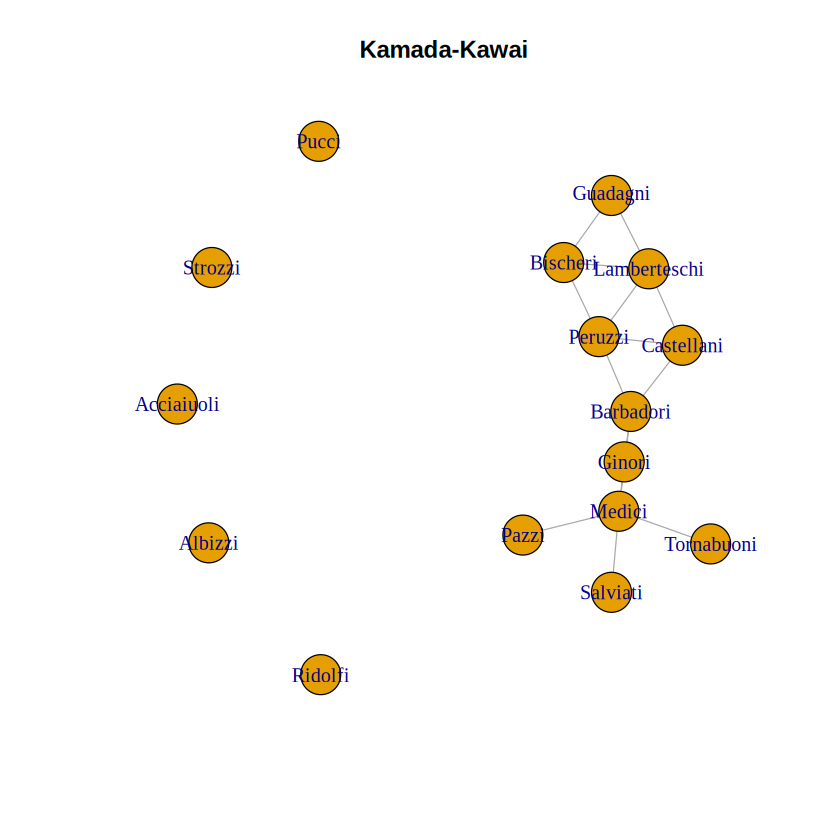

In [12]:
kk <- layout_with_kk(graph)
plot(graph, layout=kk, main="Kamada-Kawai")

2. Выявить точки сочленения и мосты сети. Подтвердить свои догадки с помощью соответствующих функций. Построить графики
сети, на котором выделены точки сочленения и мосты.

In [13]:
# Точки сочленения
articulation_points(graph)

+ 2/16 vertices, named, from 73d83a9:
[1] Medici    Barbadori

Обнаружено 2 точки сочленения - Medici и Barbadori

In [15]:
# Точки сочленения
bridges(graph)

+ 3/15 edges from 73d83a9 (vertex names):
[1] Medici--Pazzi      Medici--Salviati   Medici--Tornabuoni

3 из 15 ребёр являются мостами:
1) Medici--Pazzi
2) Medici--Salviati
3) Medici--Tornabuoni

3. Вычислить значение централизации для каждой меры. Сделать выводы.

In [16]:
# По степени
centr_degree(graph)$centralization

[1] 0.2083333

Связи распределены равномерно

In [18]:
# По близости
centr_clo(graph)$centralization

[1] NaN

Граф несвязный

In [19]:
# По посредничеству
centr_betw(graph)$centralization

[1] 0.2057143

Сеть распределена и "слухи" могут передаваться разными путями

In [20]:
# По влиятельности
centr_eigen(graph)$centralization


[1] 0.7004496

В сети присутствует кластер или нода с большим числом связей. Так как значение "по степени" низкое, это должен быть кластер, а не один участник отношений.

4. Исследовать данную сеть на предмет подгрупп с помощью 𝑘-ядер.
Указать какие подгруппы получились. Сделать выводы

In [22]:
# Подсчёт k-ядер
core <- coreness(graph)
table(core)

core
0 1 2 
5 3 8 

In [23]:
# Группировка имён узлов по уровням ядра
split(V(graph)$name,core)

$`0`
[1] "Acciaiuoli" "Albizzi"    "Pucci"      "Ridolfi"    "Strozzi"   

$`1`
[1] "Pazzi"      "Salviati"   "Tornabuoni"

$`2`
[1] "Barbadori"    "Bischeri"     "Castellani"   "Ginori"       "Guadagni"    
[6] "Lamberteschi" "Medici"       "Peruzzi"

Получились ядра:

0 ядро: Acciaiuoli, Albizzi, Pucci, Ridolfi, Strozzi. Эти семьи изолированы.

1 ядро: Pazzi, Salviati, Tornabuoni. Эти семьи "на окраине" графа.

2 ядро:
Barbadori, Bischeri, Castellani, Ginori, Guadagni, Lamberteschi, Medici, Peruzzi. Это "костяк" отношений в графе.

С каждым "уровнем"=k ядра участники "повязаны" всё больше и больше с сетью и друг-другом. По данной характеристике можно выделить категории семей и получится 3 группы.

5. С помощью библиотеки igraph исследовать алгоритмы обнаружения сообществ:  InfoMAP, Louvain, Optimal.
Кратко объяснить суть каждого алгоритма. Вывести значение модулярности и отобразить полученные сообщества. Сделать выводы.


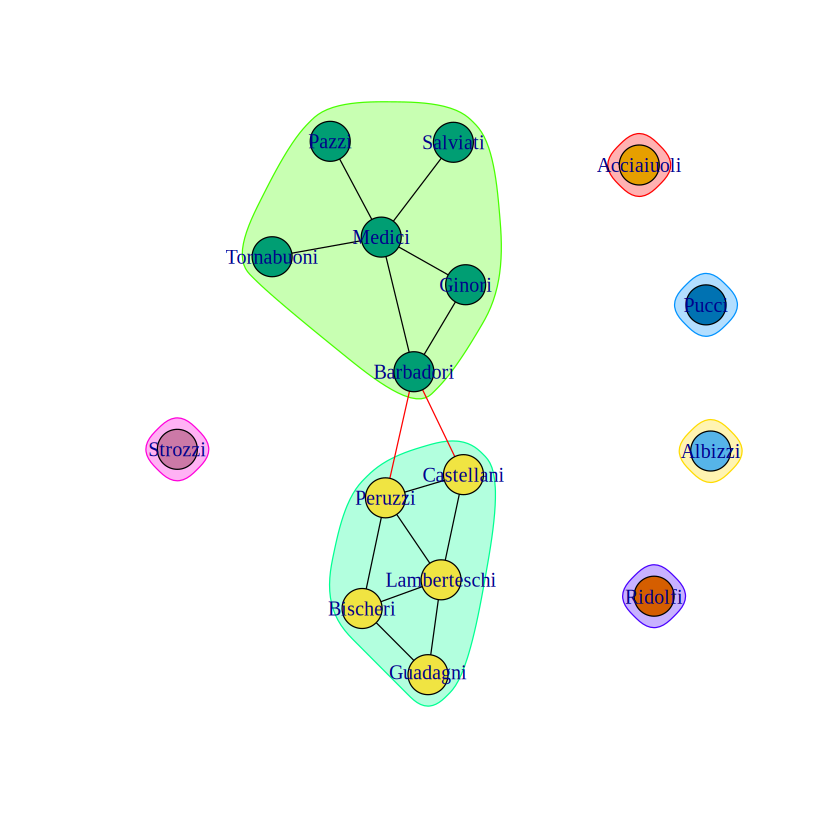

In [41]:
# Алгоритм Infomap
infomap<-cluster_infomap(graph, NULL, NULL, 1000, TRUE)
plot(infomap, graph)

Официальное описание:

"Find community structure that minimizes the expected description length of a random walker trajectory. If the graph is directed, edge directions will be taken into account."

Алгоритм случайно обходит граф - в данном случае 1000 раз - и отмечает узлы или их группы, в которых он провёл подозрительно много времени. Судя по всему это способ получить оценку тех же результатов, что и в точных методах, но через эвристику.

Ниже снова отрисован граф, чтобы было удобнее заметить, что элементы-мосты и элементы-одиночки попали в результат выполнения функции.

Предположительно будет лучше работать на ориентарованных графах.

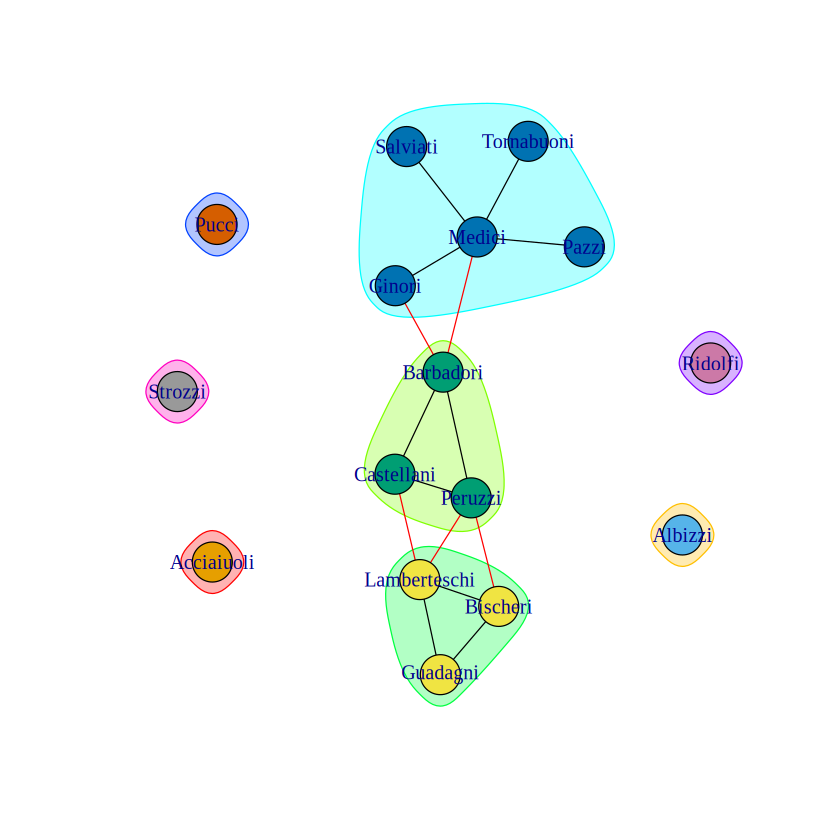

In [40]:
# Алгоритм Louvain
lou<-cluster_louvain(graph)
plot(lou, graph)

$`1`
[1] "Acciaiuoli"

$`2`
[1] "Albizzi"

$`3`
[1] "Barbadori"  "Ginori"     "Medici"     "Pazzi"      "Salviati"  
[6] "Tornabuoni"

$`4`
[1] "Bischeri"     "Castellani"   "Guadagni"     "Lamberteschi" "Peruzzi"     

$`5`
[1] "Pucci"

$`6`
[1] "Ridolfi"

$`7`
[1] "Strozzi"

[1] 0.3644444

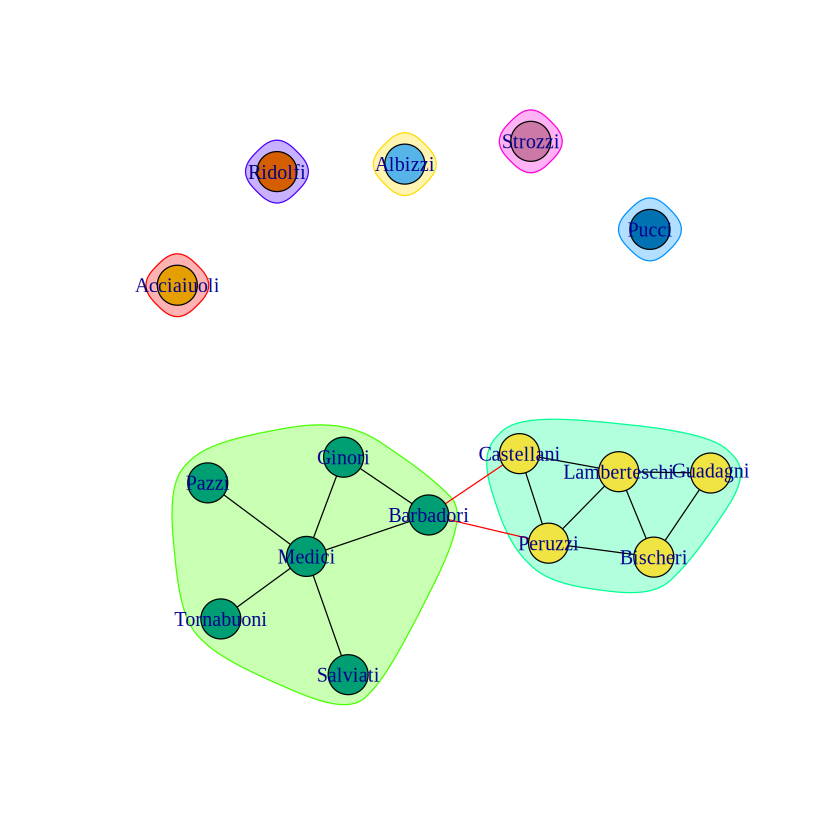

In [43]:
#
optim<-cluster_optimal(graph)
plot(optim,graph)
groups(optim)
modularity(optim)

6. Из файла ceo.csv извлечь матрицу инцидентности с помощью соответствующих функций. Отобразить полученную матрицу.

In [80]:
#
ceo<-read.csv("ceo.csv", header=TRUE, comment.char='#', check.names = FALSE)
ceo <- as.matrix(ceo)
rownames(ceo) <- paste0("CEO ", 1:nrow(ceo))
colnames(ceo) <- paste0("Club ", 1:ncol(ceo))
dim(ceo)
ceo

[1] 25 15

,Club 1,Club 2,Club 3,Club 4,Club 5,Club 6,Club 7,Club 8,Club 9,Club 10,Club 11,Club 12,Club 13,Club 14,Club 15
CEO 1,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0
CEO 2,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0
CEO 3,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1
CEO 4,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0
CEO 5,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0
CEO 6,0,0,1,1,0,0,0,0,0,1,1,0,0,0,0
CEO 7,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0
CEO 8,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0
CEO 9,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
CEO 10,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0


7. Отобразить сеть в виде биграфа.

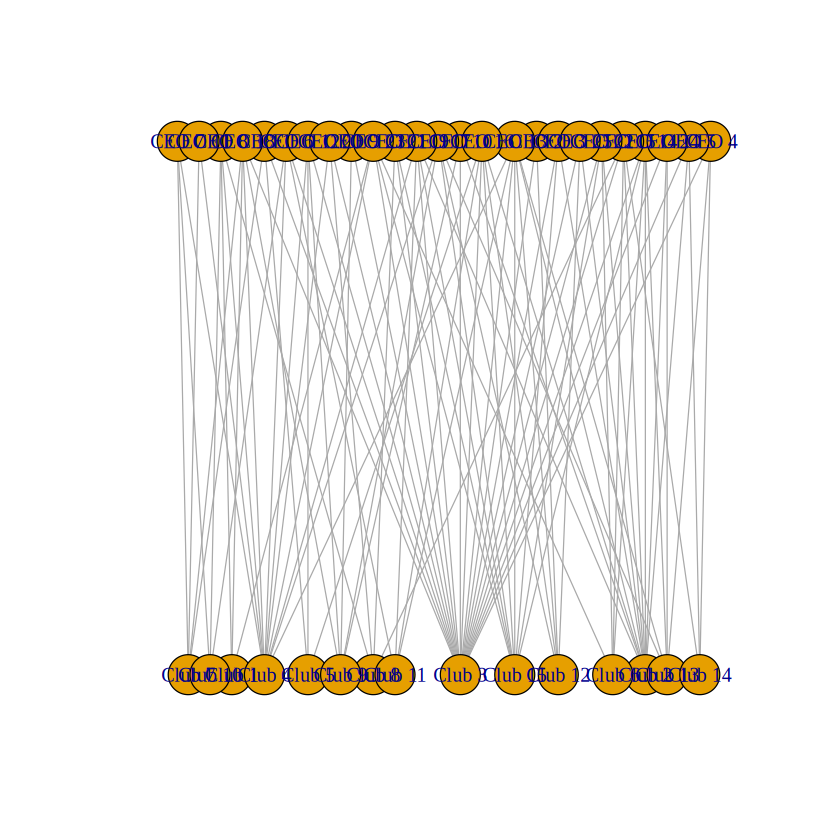

In [79]:
#
b_ceo<-graph_from_biadjacency_matrix(
ceo,
directed = FALSE,
mode = c("total"),
multiple = FALSE,
weighted = NULL,
add.names = NULL
)
plot(b_ceo, layout = layout_as_bipartite(b_ceo, types = NULL, hgap = 1, vgap = 1, maxiter = 100))

8. Дополнительное необязательное задание: отобразить сеть в виде
гиперграфа и двойственного гиперграфа.

In [82]:
#
install.packages("HyperG")
library(HyperG)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘RcppEigen’, ‘mclust’, ‘proxy’, ‘RSpectra’, ‘gtools’


Loading required package: mclust

Package 'mclust' version 6.1.4
Type 'citation("mclust")' for citing this R package in publications.


Attaching package: ‘HyperG’


The following object is masked from ‘package:network’:

    has.loops


The following objects are masked from ‘package:igraph’:

    is.simple, line.graph




ERROR: Error in HyperG(b_ceo): could not find function "HyperG"


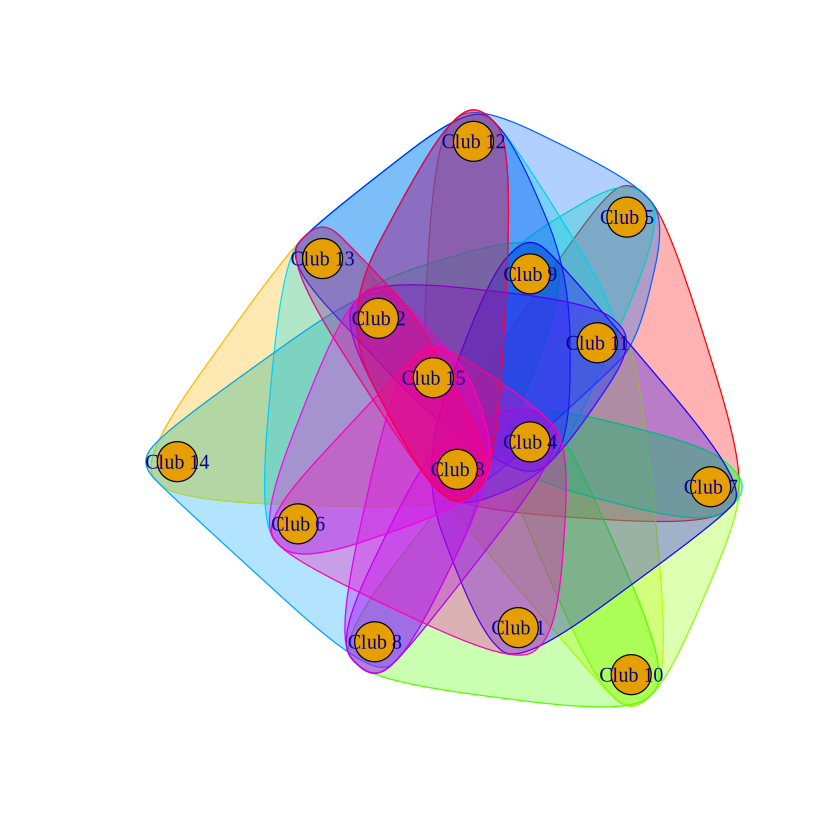

In [88]:
hg_ceo <- hypergraph_from_incidence_matrix(ceo)
plot(hg_ceo)

Каждое покрытие на картинке выше - директор

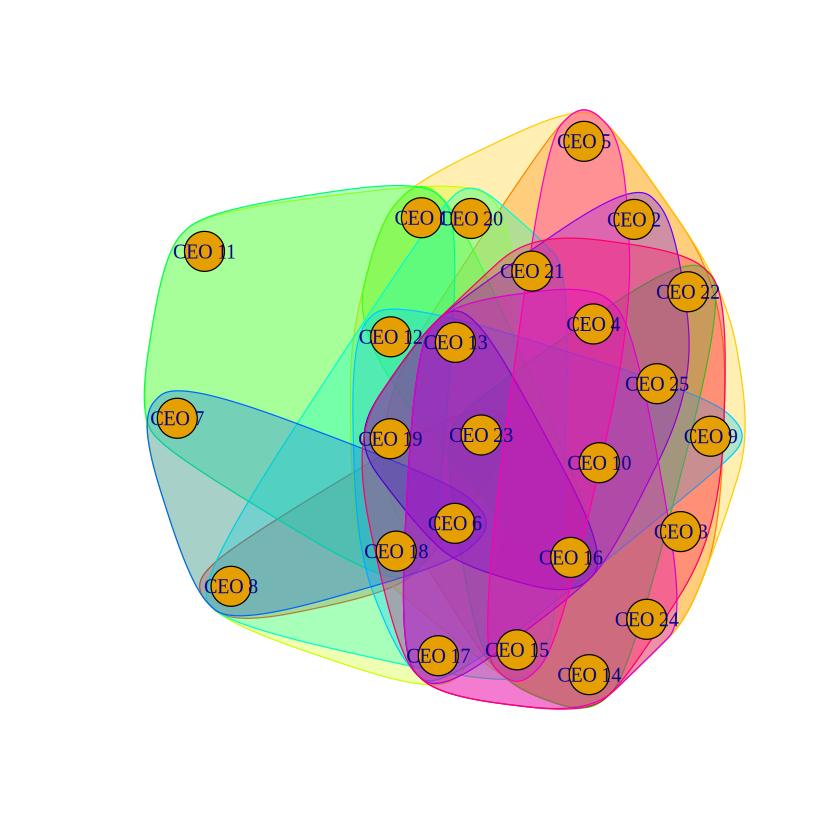

In [94]:
hg_ceo_dual <- dual_hypergraph(hg_ceo)
plot(hg_ceo_dual)

Каждое покрытие на картинке выше - клуб

Можно заметить, что из-за большого числа участников отношений всё ещё тяжело точно сравнить разные клубы и директоров, но возможно дать грубую оценку по некоторым из них с точки зрения популярности и активности относительно других участников отношений.

9. Представить сеть аффилированности в виде двух одномодальных
сетей: сеть совместного участия акторов и сеть перекрытия событий. Представить полученные сети в виде матриц и взвешенных
графов. Сделать выводы.

In [96]:
library(igraph)

In [108]:
# Получили и вывели на экран две одномодальные сети из биграфа
proj <- bipartite_projection(b_ceo)
g_actors <- proj$proj1
g_events <- proj$proj2

In [119]:
as_adjacency_matrix(g_actors)
as_adjacency_matrix(g_events)

  [[ suppressing 25 column names ‘CEO 1’, ‘CEO 2’, ‘CEO 3’ ... ]]



25 x 25 sparse Matrix of class "dgCMatrix"
                                                        
CEO 1  . 1 1 1 1 1 1 . 1 1 1 1 1 1 1 1 . 1 1 1 1 1 1 1 1
CEO 2  1 . 1 1 1 1 . . 1 1 . 1 1 1 1 1 1 1 1 1 1 1 1 1 1
CEO 3  1 1 . 1 1 1 . . 1 1 . 1 1 1 1 1 1 1 1 1 1 1 1 1 1
CEO 4  1 1 1 . 1 1 . . 1 1 . 1 1 1 1 1 1 1 1 1 1 1 1 1 1
CEO 5  1 1 1 1 . 1 . . 1 1 . 1 1 1 1 1 . 1 1 1 1 1 1 1 1
CEO 6  1 1 1 1 1 . 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
CEO 7  1 . . . . 1 . 1 . . 1 1 1 . . . 1 1 1 1 . . 1 . .
CEO 8  . . . . . 1 1 . . . 1 1 1 . 1 . 1 1 1 1 1 . 1 . .
CEO 9  1 1 1 1 1 1 . . . 1 . 1 1 1 1 1 1 1 1 1 1 1 1 1 1
CEO 10 1 1 1 1 1 1 . . 1 . . 1 1 1 1 1 1 1 1 1 1 1 1 1 1
CEO 11 1 . . . . 1 1 1 . . . 1 1 . . . 1 1 1 1 . . 1 . .
CEO 12 1 1 1 1 1 1 1 1 1 1 1 . 1 1 1 1 1 1 1 1 1 1 1 1 1
CEO 13 1 1 1 1 1 1 1 1 1 1 1 1 . 1 1 1 1 1 1 1 1 1 1 1 1
CEO 14 1 1 1 1 1 1 . . 1 1 . 1 1 . 1 1 1 1 1 1 1 1 1 1 1
CEO 15 1 1 1 1 1 1 . 1 1 1 . 1 1 1 . 1 . 1 1 1 1 1 1 1 1
CEO 16 1 1 1 1 1 1 . . 1 1 . 1 1 1 1 . 1 1 1 

  [[ suppressing 15 column names ‘Club 1’, ‘Club 2’, ‘Club 3’ ... ]]



15 x 15 sparse Matrix of class "dgCMatrix"
                                     
Club 1  . . 1 1 . 1 1 1 1 1 . . . . 1
Club 2  . . 1 1 1 1 . 1 1 . 1 1 1 1 1
Club 3  1 1 . 1 1 1 1 1 1 1 1 1 1 1 1
Club 4  1 1 1 . 1 1 1 1 1 1 1 1 1 . 1
Club 5  . 1 1 1 . . 1 . 1 . 1 1 . . 1
Club 6  1 1 1 1 . . . 1 . . . . 1 1 1
Club 7  1 . 1 1 1 . . . 1 1 . . . . .
Club 8  1 1 1 1 . 1 . . . 1 . . . 1 1
Club 9  1 1 1 1 1 . 1 . . . . 1 1 . 1
Club 10 1 . 1 1 . . 1 1 . . 1 . . . .
Club 11 . 1 1 1 1 . . . . 1 . 1 1 . 1
Club 12 . 1 1 1 1 . . . 1 . 1 . 1 . 1
Club 13 . 1 1 1 . 1 . . 1 . 1 1 . 1 1
Club 14 . 1 1 . . 1 . 1 . . . . 1 . .
Club 15 1 1 1 1 1 1 . 1 1 . 1 1 1 . .

$vcount1
[1] 25

$ecount1
[1] 259

$vcount2
[1] 15

$ecount2
[1] 66

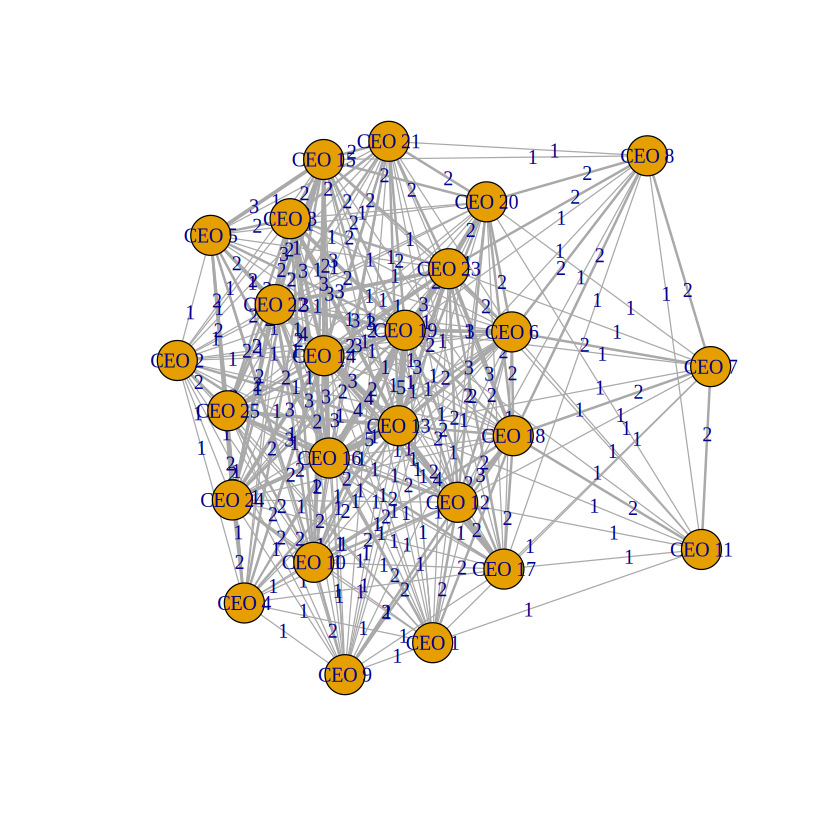

In [117]:
plot(g_actors, edge.width=E(g_actors)$weight, edge.label=E(g_actors)$weight)
bipartite_projection_size(b_ceo)


Видно, что большинство директоров разделяют один или два общих клуба в смысле посещения.

$vcount1
[1] 25

$ecount1
[1] 259

$vcount2
[1] 15

$ecount2
[1] 66

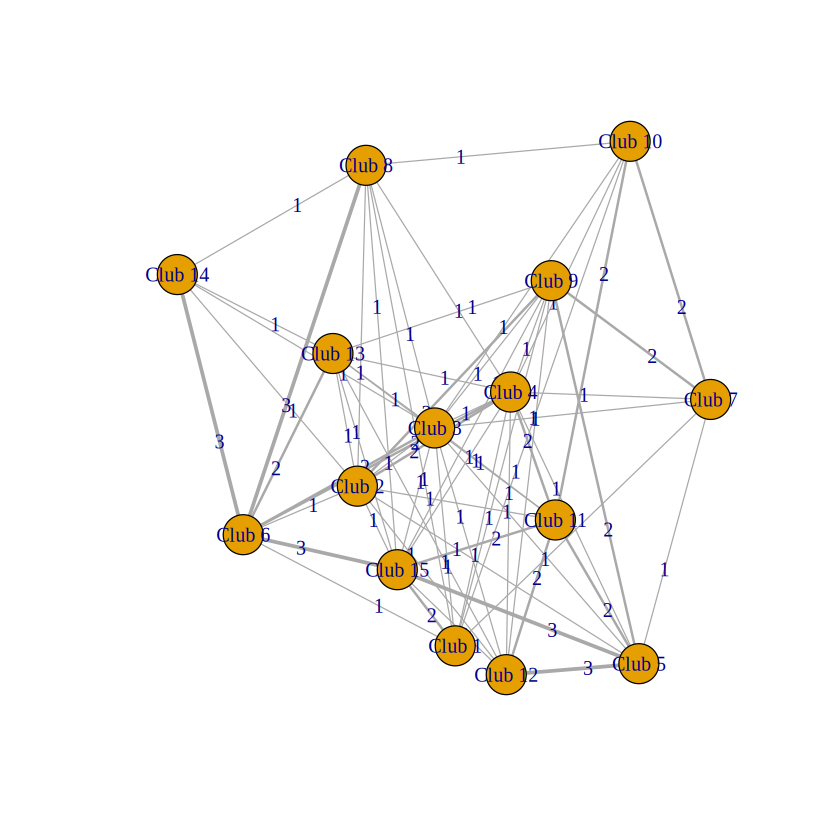

In [120]:
plot(g_events, edge.width=E(g_actors)$weight, edge.label=E(g_actors)$weight)
bipartite_projection_size(b_ceo)

В данном представлении заметно, что есть клубы, которые посещает много общих директоров - к примеру, видно числа 3 - можно сделать предположение, что они тематически близки (как стрельбище и охота, к примеру), что приводит к такой ситуации.

10. Вычислить степень участия для каждого актора, а также среднее
количество событий, с которыми актор аффилирован. Сделать выводы.

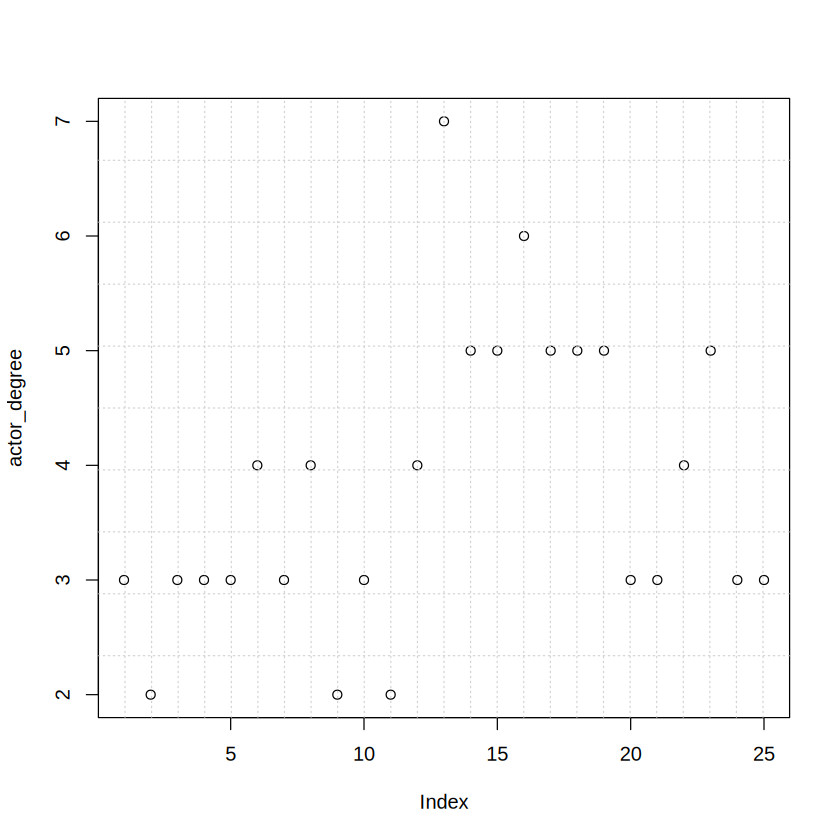

In [126]:
#
actor_degree <- rowSums(ceo)
plot(actor_degree)
grid(nx=26,ny=10)

Наглядное представление степени участия каждого актора (директора)

[1] 3.8

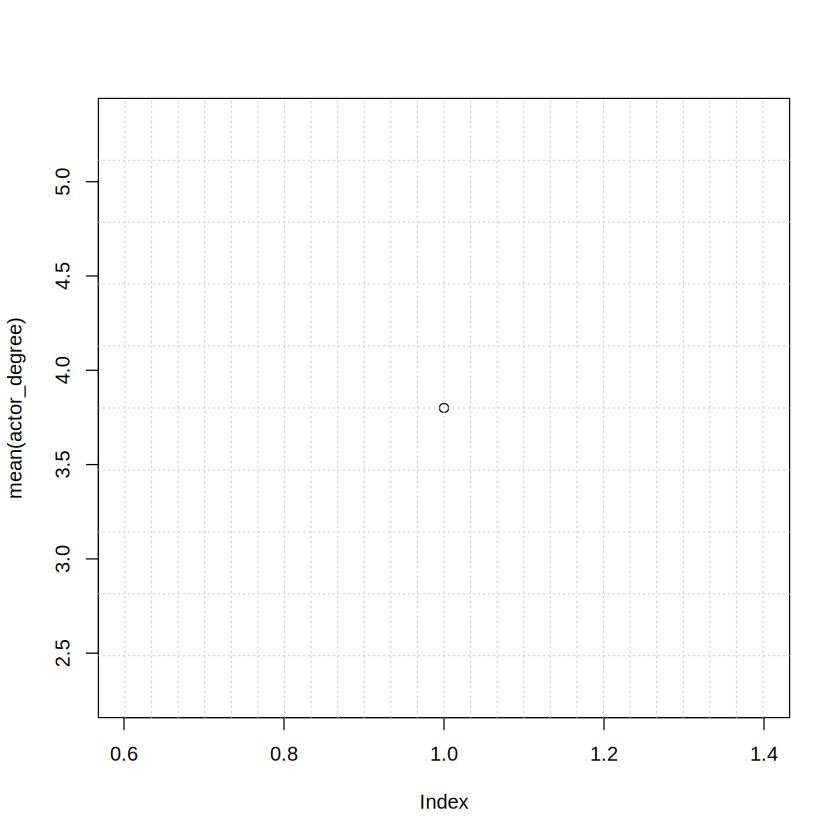

In [131]:
mean(actor_degree)
plot(mean(actor_degree))
grid(nx=26,ny=10)

В 3.8 клубах в среднем состоит отдельно взятый случайный директор, причём большинство участвует или в 3, или в 5 клубах, пусть и существуют исключительные персоналии.

11. Вычислить размер и средний размер для каждого события. Сделать выводы.

[1] 6.333333

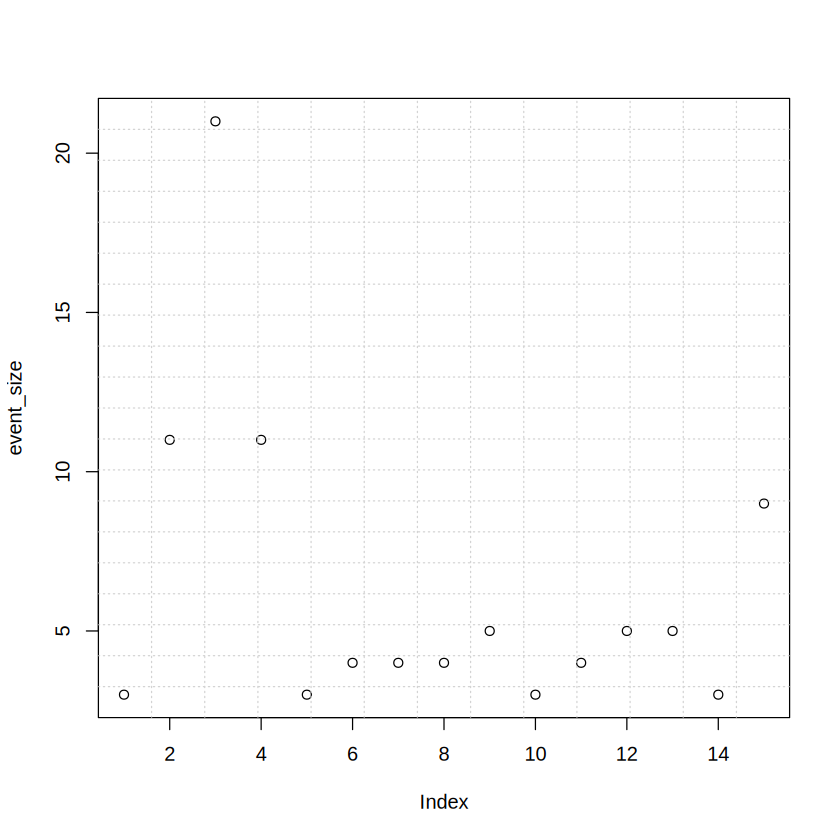

In [152]:
event_size <- colSums(ceo)
mean(event_size)
plot(event_size)
grid(nx=13,ny=20)

Среднее число участников клуба чуть больше, чем 6 человек - эта оценка звучит неубедительно, если посмотреть на вышевыведенный график, на котором большинство точек существуют на уровне ниже 5. Вероятно несколько особо популярных клубов привели к размытию среднего числа и медианная оценка тут была бы уместнее - посмотрим и её ради интереса:

[1] 4

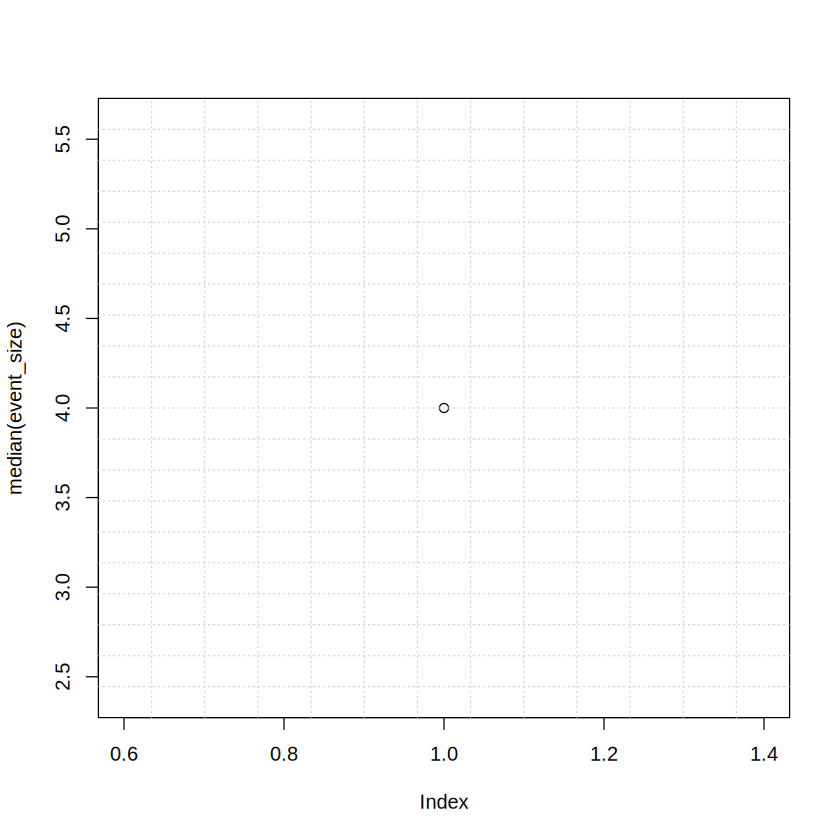

In [155]:
median(event_size)
plot(median(event_size))
grid(nx=13,ny=20)

Да, выглядит точнее.

12. Вычислить плотность для отношения совместного участия акторов
и отношения перекрытия. Проинтерпретируйте полученные значения.

In [157]:
edge_density(g_actors)

[1] 0.8633333

Большая часть всех возможных пар директоров являются общими знакомыми по клубу.

In [158]:
edge_density(g_events)

[1] 0.6285714

Одновременно с этим, лишь 62.9% клубов имеют хотя бы одного общего участника, что можно интерпретировать как разрозненность в тематическом смысле.

13. Определить диаметр сети аффилированности.

In [159]:
diameter(b_ceo)

[1] 5

In [161]:
diameter(g_actors, weights=NA)

[1] 2

In [162]:
diameter(g_events, weights=NA)

[1] 2

Для начала рассмотрим разницу в выводе функции при условии наличия или отсутствия аргумента (weights=NA):

In [163]:
na<-diameter(g_actors, weights=NA)
empty<-diameter(g_actors)
na-empty

na<-diameter(g_events, weights=NA)
empty<-diameter(g_events)
na-empty

[1] -1

[1] -2

Результат отличен от нуля, так как функция учитывает веса в расчётах - поэтому дадим комментарий без их учёта.

Вся сеть обладает диаметром 5, что, учитывая число вершин, можно интерпретировать как высокую возможность для распространения слухов и информации среди участников отношений, причём "секреты" отсутствуют как между директорами, так и клубами, так как диаметр у обоих равен 2, что тоже является весьма маленьким числом (к примеру, в среднем по планете это число равно 6).

14. Для каждых пар событий определить (логарифм) отношение шансов. Сделать выводы.

Для каждой пары из events мы можем рассмотреть частоту участия акторов в событии при условия участия в ином событии - вновь идея общей тематики клубов.

$$ \frac{"both" \times "none"}{\text{"only-first"} \times \text{"only-second"}}$$

Так выглядит формулы для расчёта этой характеристики для двух событий, где каждая переменная - число акторов, удовлетворяющих условию. Для логарифма - взять $ln()$ от результата.

In [166]:
C <- as.matrix(ceo) # матрица смежности
a <- nrow(C) # число акторов

both<-t(C)%*%C
none<-t(C)%*%(1-C)
OF<-t(1-C)%*%C
OS<-t(1-C)%*%(1-C)

log_res <- log(((both+0.5)*(none+0.5))/((OF+0.5)*(OS+0.5)))
diag(log_res)<-NA

round(log_res, 2)

,Club 1,Club 2,Club 3,Club 4,Club 5,Club 6,Club 7,Club 8,Club 9,Club 10,Club 11,Club 12,Club 13,Club 14,Club 15
Club 1,NA,-4.33,-2.90,-4.25,-3.66,-2.90,-2.90,-2.90,-3.10,-2.61,-3.86,-4.01,-4.01,-3.66,-3.49
Club 2,-1.95,NA,-2.11,-0.79,-0.69,0.38,-2.11,-0.94,-1.10,-1.95,0.38,-0.05,-0.05,0.16,-0.12
Club 3,2.23,3.98,NA,3.88,3.36,3.56,2.05,2.51,2.71,1.59,3.56,2.71,2.71,3.36,3.08
Club 4,1.41,-0.79,1.54,NA,-0.69,-0.94,0.38,-0.27,-0.05,1.41,0.38,-0.53,-0.53,-1.95,-0.44
Club 5,-3.66,-3.56,-3.86,-3.56,NA,-3.86,-2.90,-3.86,-3.10,-3.66,-2.90,-3.10,-4.01,-3.66,-3.49
Club 6,-2.23,-3.08,-3.56,-3.14,-3.36,NA,-3.56,-2.51,-3.70,-3.36,-3.56,-3.70,-2.71,-2.23,-2.95
Club 7,-2.23,-3.98,-2.05,-3.08,-2.23,-3.56,NA,-3.56,-2.71,-2.23,-3.56,-3.70,-3.70,-3.36,-3.97
Club 8,-2.23,-3.14,-2.51,-2.94,-3.36,-2.51,-3.56,NA,-3.70,-2.23,-3.56,-3.70,-3.70,-2.23,-3.08
Club 9,-1.92,-2.79,-2.21,-2.50,-1.92,-3.30,-2.21,-3.30,NA,-3.10,-3.30,-2.40,-2.40,-3.10,-2.76
Club 10,-2.61,-4.33,-2.61,-4.25,-3.66,-3.86,-2.90,-2.90,-4.01,NA,-2.90,-4.01,-4.01,-3.66,-4.29


Из-за деления на ноль во многих ячейках матрицы получался Inf - в литературе указывается, что принято добавлять 0.5 в таких ситуациях, что и было сделано.

Интерпретировать эту информацию можно таким образом: если человек состоит в клубе I, то каков шанс, что ему захочется быть участником клуба J, где число в матрице на позиции $c_{ij} -$ это оценка этой возможности: чем дальше она от нуля в положительную сторону, тем шанс выше; для обратного верно обратное; для нуля отсутствие корреляции.

15. Сделать общий вывод по работе.

Анализ данных позволяет получить информацию о сути происходящих явлений.

В данном случае удалось убедиться, что статистические методы вернули информацию схожую с той, что была получена в 1 практической работе для Флорентийских бизнесменов, но другими путями.

Что касается клубов и бизнесменов, возможность извлечь тематические направленности исключительно из матрицы смежности - это сильный инструмент, чтобы анализировать, к примеру, эффективность логистики или предсказывать популярность клуба / поведение человека при добавлении его в уже сложившуюся систему.

Конкретные выводы по численным характеристикам приведены в соответствующих пунктах практической работы.